# Personal recordings: measure first, then compare with what you intended
Goal: reliable note events for eventual tablature, not matching a known phrase
by feeding it to the predictor. Expected notes live in session metadata and
never enter frequency estimation, acceptance or grouping.
Use the actual 44.1 kHz sample rate. Keep the existing 100 ms / 20 ms pitch
windows, 60–1,000 Hz bounds, 3x / 0.80 / 50-cent checks and current grouping.
Energy-rise measurements use the separate 10 ms / 2 ms / 40 ms settings.
This lesson does not use an attack detector or split events by attacks.
Notebook 09 now proposes attacks independently; pitch grouping here stays fixed.

Before running: which should fail first at higher speed—frequency estimation,
filtering, or grouping? A 100 ms window can contain parts of several short
notes. A failure to produce a group need not mean no note was played.


In [1]:
from pathlib import Path
import csv
import hashlib
import json
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from pitch_analysis import estimate_period
from note_events import group_pitch_windows
from attack_analysis import measure_energy_rise

manifest_path = Path('data/recording_sessions/2026-11-03_personal_takes.json')
session = json.loads(manifest_path.read_text())
output_folder = Path('outputs/pitch_tracking/personal_2026-11-03')
output_folder.mkdir(parents=True, exist_ok=True)
window_seconds, hop_seconds = 0.100, 0.020
minimum_frequency, maximum_frequency = 60., 1000.
minimum_level_ratio, minimum_similarity, maximum_step_cents = 3., .80, 50.
recordings = {item['id']: Path(item['path']) for item in session['recordings']}
print('Reported setup:', session['reported_setup'])
print('Intended phrase (comparison only):', ' '.join(session['intended_phrase_pitch_classes']))


Reported setup: {'pickup': 'neck + middle', 'tone': 'pretty dry (user description; processing not independently confirmed)', 'metronome': False, 'interface_gain': 'not yet confirmed for this batch', 'export_normalization': 'not yet confirmed'}
Intended phrase (comparison only): A G E D G E D C E D C A


## 1. Inspect a provisional background reference
Exact-zero padding is not background noise. The DynamicsAdded file has a
quiet-looking nonzero interval at 1.2–1.4 s. Use median 100 ms RMS from complete
windows inside that interval, on the ORIGINAL 20 ms grid. This is a manual,
provisional shared reference; equal gain and quiet playing status are not yet
confirmed. We do not fit a separate threshold to make each take look good.
A wrong reference can reject quiet notes or admit noise. Raw estimates remain
visible, so we can distinguish the pitch model from the acceptance rule.


Candidate reference: 0.00002170, 6 overlapping windows; visually/level-selected candidate quiet interval; user confirmation pending; shared provisionally across batch


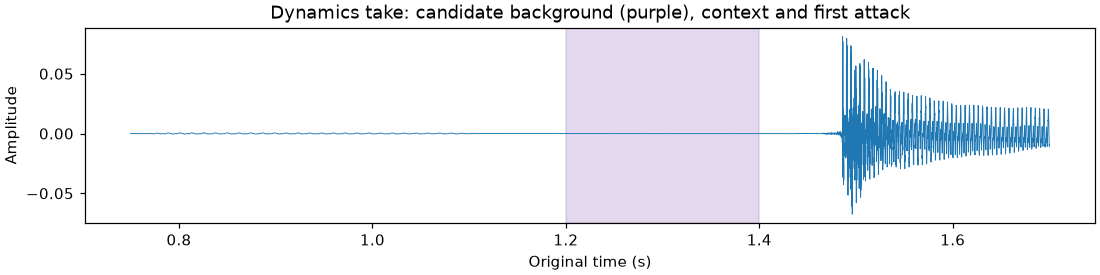

In [2]:
reference = session['background_reference']
ref_path = recordings[reference['source_id']]
ref_audio, ref_rate = sf.read(ref_path)
ref_signal = ref_audio[:, 0] if ref_audio.ndim == 2 else ref_audio
ref_start, ref_stop = [round(reference[key] * ref_rate) for key in ('start_seconds', 'stop_seconds')]
ref_width, ref_hop = round(window_seconds * ref_rate), round(hop_seconds * ref_rate)
ref_values = []
for start in range(0, len(ref_signal) - ref_width + 1, ref_hop):
    if start >= ref_start and start + ref_width <= ref_stop:
        ref_values.append(float(np.sqrt(np.mean(ref_signal[start:start + ref_width] ** 2))))
if not ref_values or np.median(ref_values) <= 0:
    raise ValueError('Choose a nonzero reference with complete windows; never divide by digital silence.')
reference_rms = float(np.median(ref_values))
print(f'Candidate reference: {reference_rms:.8f}, {len(ref_values)} overlapping windows; {reference["status"]}')
fig, ax = plt.subplots(figsize=(10, 2.5), constrained_layout=True)
first, last = round(.75 * ref_rate), round(1.7 * ref_rate)
ax.plot(np.arange(first, last) / ref_rate, ref_signal[first:last], linewidth=.6)
ax.axvspan(reference['start_seconds'], reference['stop_seconds'], color='tab:purple', alpha=.25)
ax.set(title='Dynamics take: candidate background (purple), context and first attack', xlabel='Original time (s)', ylabel='Amplitude')
fig.savefig(output_folder / 'reference_review.png', dpi=130)
plt.show()


## 2. Apply the existing pipeline to each full file
WAV → single-window pitch/RMS/score → unchanged checks → evidence groups.
In parallel: WAV → short-window RMS rise (an observation, not an attack list).
Input WAVs remain untouched. No denoising, resampling, normalization, pitch
correction, expected-note snapping, gap filling or minimum-duration pruning.
One new pluck of an unchanged pitch may remain inside one long group.


In [3]:
results = {}
for identifier, path in recordings.items():
    source_hash = hashlib.sha256(path.read_bytes()).hexdigest()
    audio, rate = sf.read(path)
    info = sf.info(path)
    signal = audio[:, 0] if audio.ndim == 2 else audio
    width, hop = round(window_seconds * rate), round(hop_seconds * rate)
    rows = []
    previous_hz, previous_eligible = np.nan, False
    for start in range(0, len(signal) - width + 1, hop):
        segment = signal[start:start + width]
        hz, lag, score = estimate_period(segment, rate, minimum_frequency, maximum_frequency)
        rms = float(np.sqrt(np.mean(segment ** 2)))
        ratio = rms / reference_rms
        finite = bool(np.isfinite(hz) and hz > 0)
        level_ok = bool(ratio >= minimum_level_ratio)
        repetition_ok = bool(np.isfinite(score) and score >= minimum_similarity)
        eligible = finite and level_ok and repetition_ok
        step = abs(1200 * np.log2(hz / previous_hz)) if finite and np.isfinite(previous_hz) and previous_hz > 0 else np.nan
        continuity_ok = bool(previous_eligible and np.isfinite(step) and step <= maximum_step_cents)
        accepted = bool(eligible and continuity_ok)
        reasons = []
        if not finite: reasons.append('no_finite_pitch')
        if not level_ok: reasons.append('low_relative_level')
        if not repetition_ok: reasons.append('weak_repetition')
        if not previous_eligible: reasons.append('needs_previous_eligible_window')
        elif finite and step > maximum_step_cents: reasons.append('pitch_change')
        rows.append(dict(source_file=path.name, sample_rate=rate, start_sample=start,
            stop_sample_exclusive=start + width, midpoint_seconds=(start + width / 2) / rate,
            rms=rms, candidate_hz=hz, lag_samples=lag, similarity=score, level_ratio=ratio,
            level_ok=level_ok, repetition_ok=repetition_ok, continuity_ok=continuity_ok,
            step_cents=step, accepted=accepted, accepted_hz=hz if accepted else np.nan,
            rejection_reasons=';'.join(reasons), reference_rms=reference_rms,
            reference_source=str(ref_path), reference_start_sample=ref_start, reference_stop_sample_exclusive=ref_stop,
            minimum_level_ratio=minimum_level_ratio, minimum_similarity=minimum_similarity,
            maximum_step_cents=maximum_step_cents))
        previous_hz, previous_eligible = hz, eligible
    events = group_pitch_windows(rows, hop)
    energy = measure_energy_rise(signal, rate)
    assert sum(e['window_count'] for e in events) == sum(r['accepted'] for r in rows)
    assert hashlib.sha256(path.read_bytes()).hexdigest() == source_hash
    for suffix, table in [('windows', rows), ('note_evidence', events), ('energy_rise', energy)]:
        if table:
            with (output_folder / f'{identifier}_{suffix}.csv').open('w', newline='') as handle:
                writer = csv.DictWriter(handle, fieldnames=list(table[0]))
                writer.writeheader(); writer.writerows(table)
    audit = dict(file=path.name, sha256=source_hash, sample_rate=rate, subtype=info.subtype,
        channels=info.channels, identical_channels=bool(np.array_equal(audio[:, 0], audio[:, 1])) if info.channels==2 else None,
        duration_seconds=len(signal)/rate, peak=float(np.max(abs(signal))),
        samples_at_or_above_0p999=int(np.sum(abs(signal)>=.999)),
        zero_fraction=float(np.mean(signal==0)), total_windows=len(rows),
        accepted_windows=sum(r['accepted'] for r in rows), event_count=len(events))
    results[identifier] = dict(rows=rows, events=events, energy=energy, signal=signal, audit=audit)
    print(f'\n{identifier}: {audit["duration_seconds"]:.3f}s, {audit["accepted_windows"]}/{len(rows)} windows pass, {len(events)} evidence groups.')
    print('Observed group sequence:', ' '.join(e['note_name'] for e in events))
    for e in events:
        print(f"  {e['note_name']:4s} {e['first_midpoint_seconds']:6.2f}–{e['last_midpoint_seconds']:6.2f}s "
              f"{e['window_count']:3d} windows; {e['median_hz']:.2f} Hz")
with (output_folder / 'audit.json').open('w') as handle:
    json.dump({key:value['audit'] for key,value in results.items()}, handle, indent=2)



baseline: 7.427s, 232/367 windows pass, 12 evidence groups.
Observed group sequence: A3 G3 E3 D3 G3 E3 D3 C3 E3 D3 C3 A2
  A3     1.41–  1.71s  16 windows; 220.50 Hz
  G3     1.79–  2.05s  14 windows; 196.88 Hz
  E3     2.15–  2.43s  15 windows; 164.55 Hz
  D3     2.51–  2.81s  16 windows; 147.49 Hz
  G3     2.87–  3.21s  18 windows; 196.88 Hz
  E3     3.31–  3.55s  13 windows; 165.17 Hz
  D3     3.65–  3.93s  15 windows; 147.00 Hz
  C3     4.01–  4.29s  15 windows; 130.47 Hz
  E3     4.37–  4.73s  19 windows; 165.17 Hz
  D3     4.81–  5.03s  12 windows; 148.74 Hz
  C3     5.13–  5.43s  16 windows; 131.06 Hz
  A2     5.51–  6.75s  63 windows; 109.98 Hz

dynamics: 10.400s, 403/515 windows pass, 13 evidence groups.
Observed group sequence: E2 A3 G3 E3 D3 G3 E3 D3 C3 E3 D3 C3 A2
  E2     0.81–  1.09s  15 windows; 82.28 Hz
  A3     1.51–  1.93s  22 windows; 220.50 Hz
  G3     1.99–  2.33s  18 windows; 197.76 Hz
  E3     2.43–  2.67s  13 windows; 165.17 Hz
  D3     2.81–  3.09s  15 windows

## 3. Read the stages together for all five takes
Waveform: original amplitude and timing. Pitch: all raw candidates plus green
accepted estimates. Similarity: the existing 0.80 line. Energy-rise curve:
how far current 10 ms RMS rises above the previous 40 ms median.
A rise isn't automatically a pluck. A green pitch isn't a correctness probability.
Expected note names are NOT assigned timestamps or stretched to fit the playing.
Without true note boundaries, no per-window or onset accuracy score is reported.


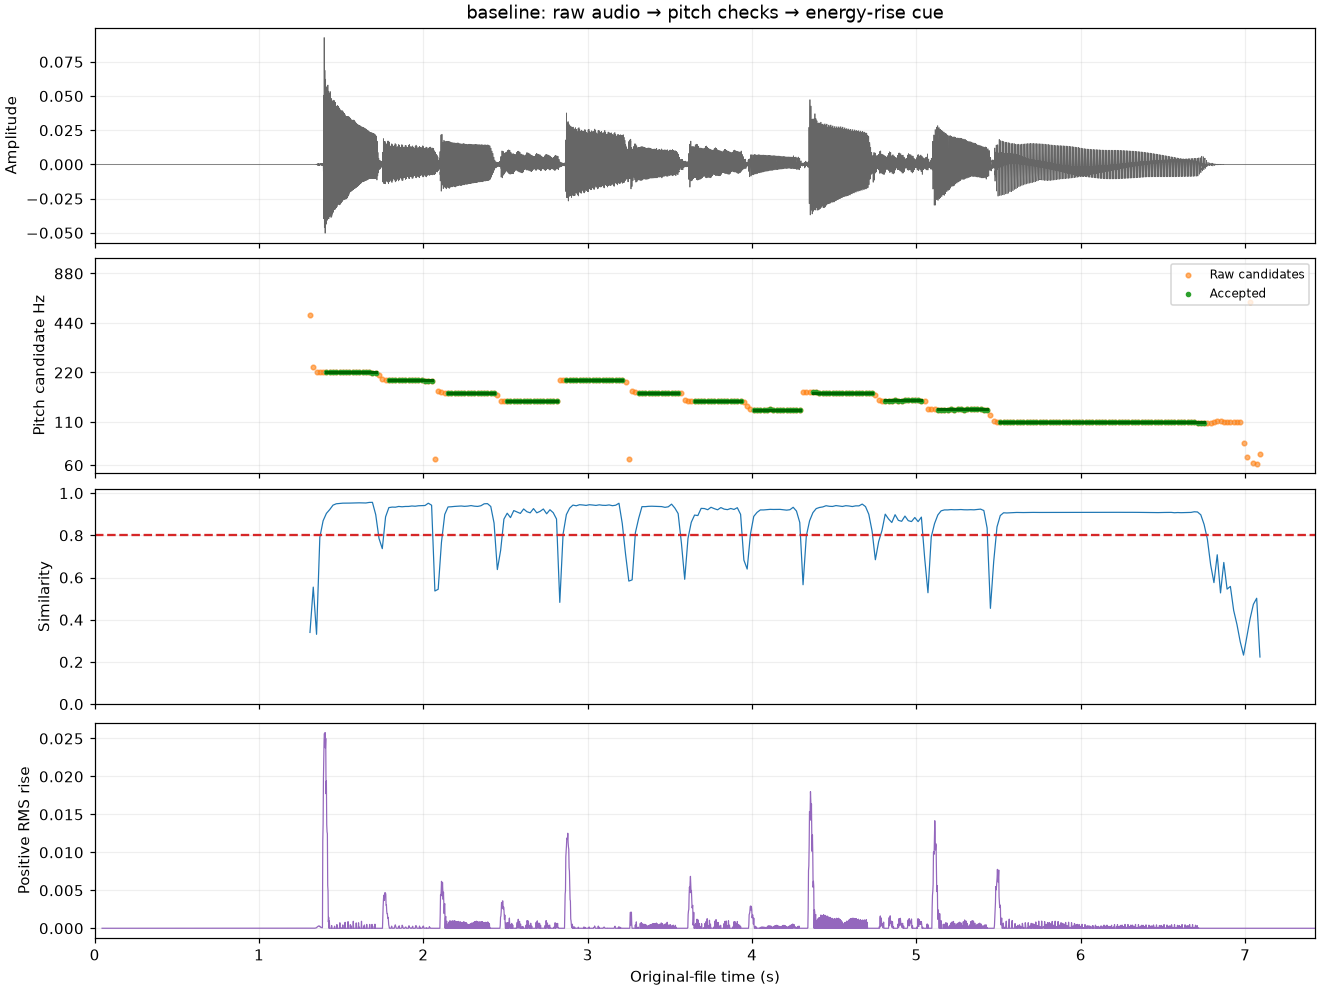

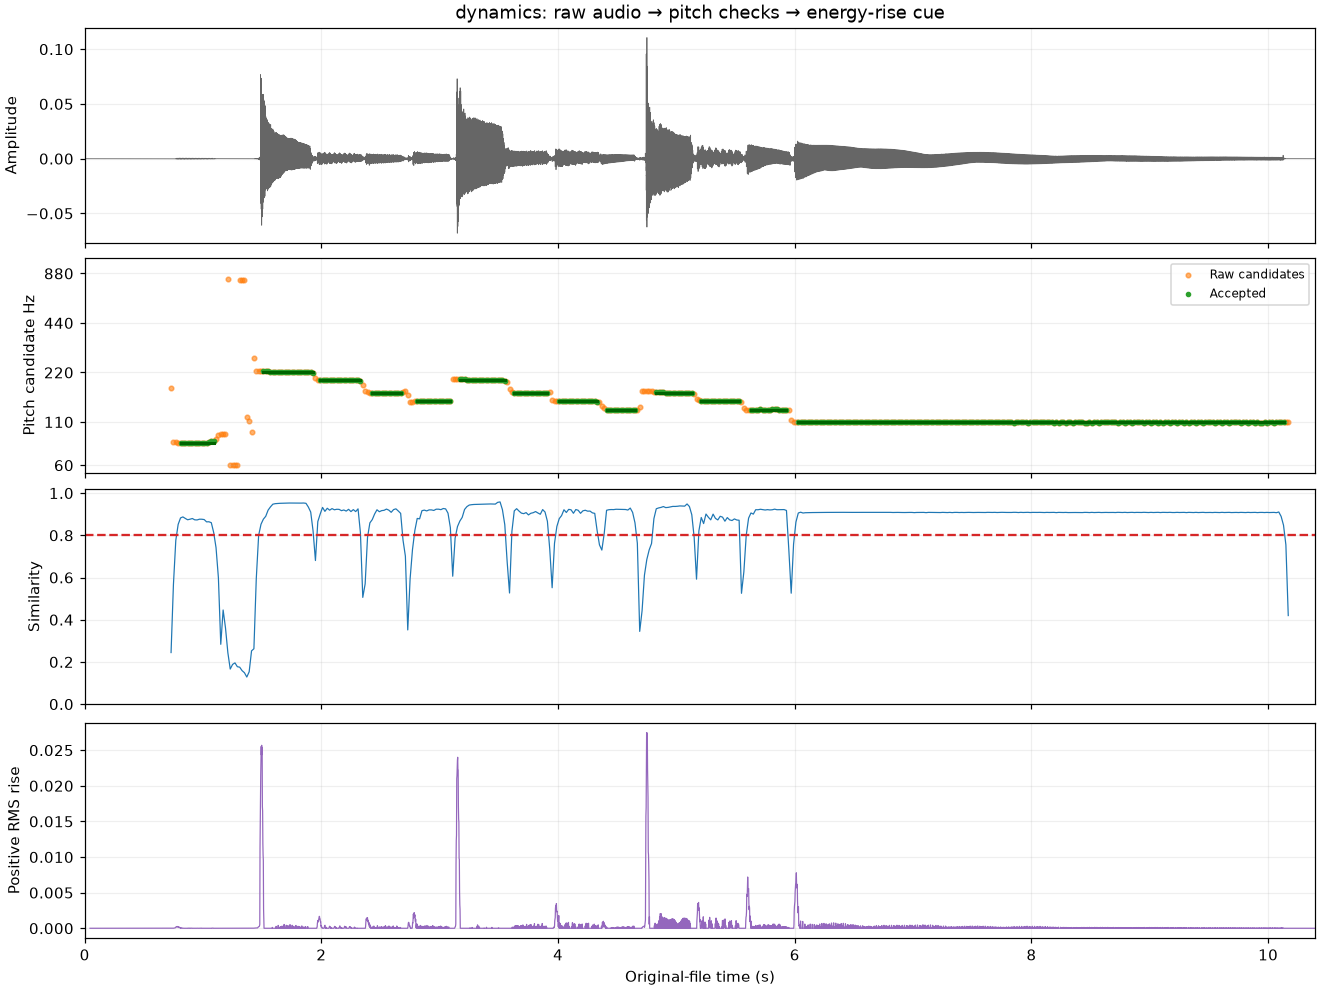

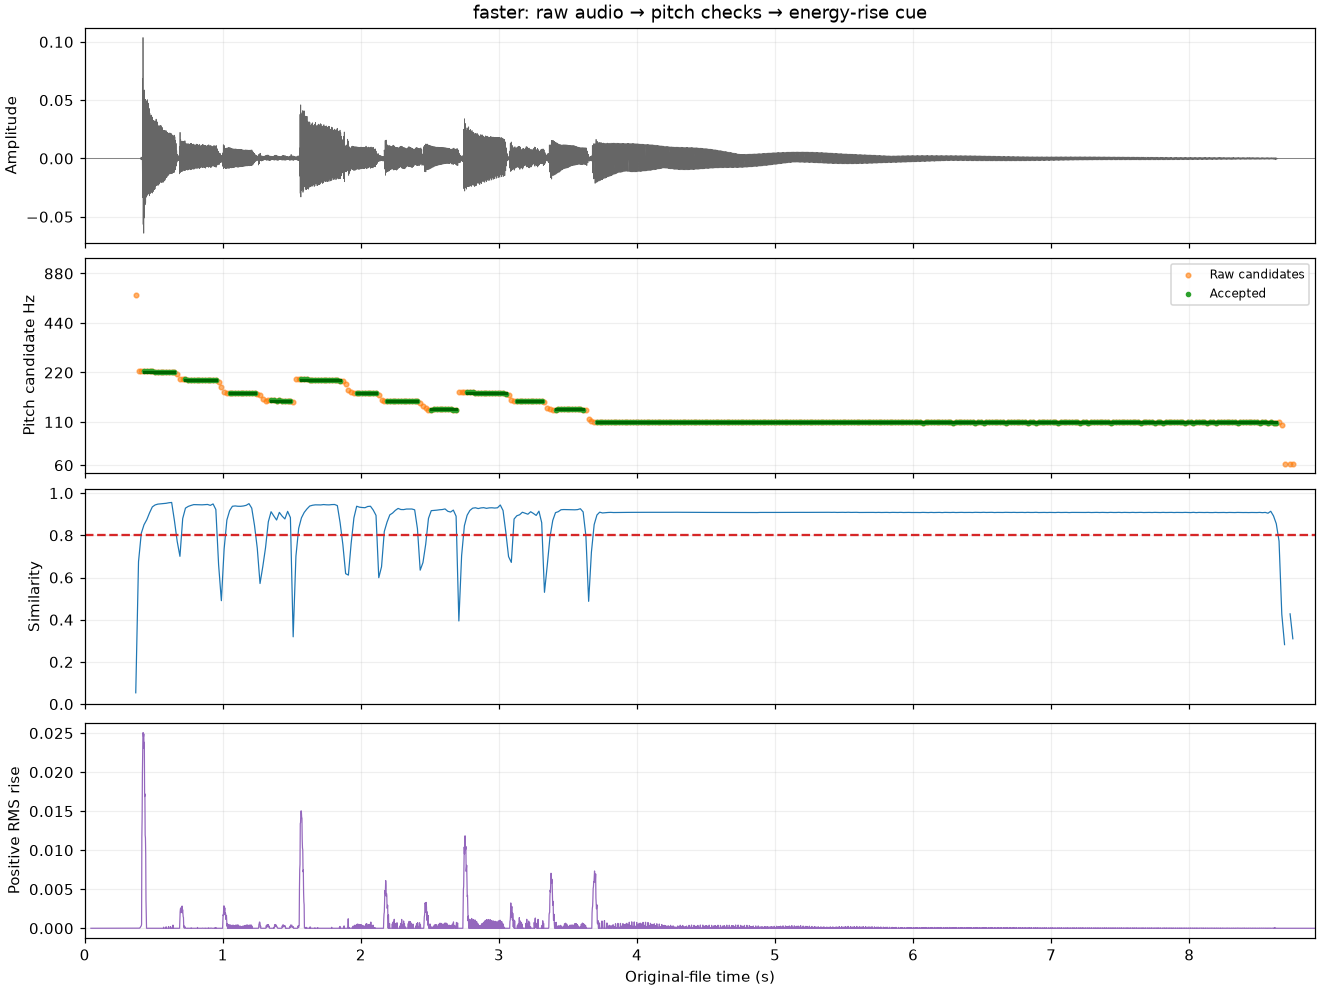

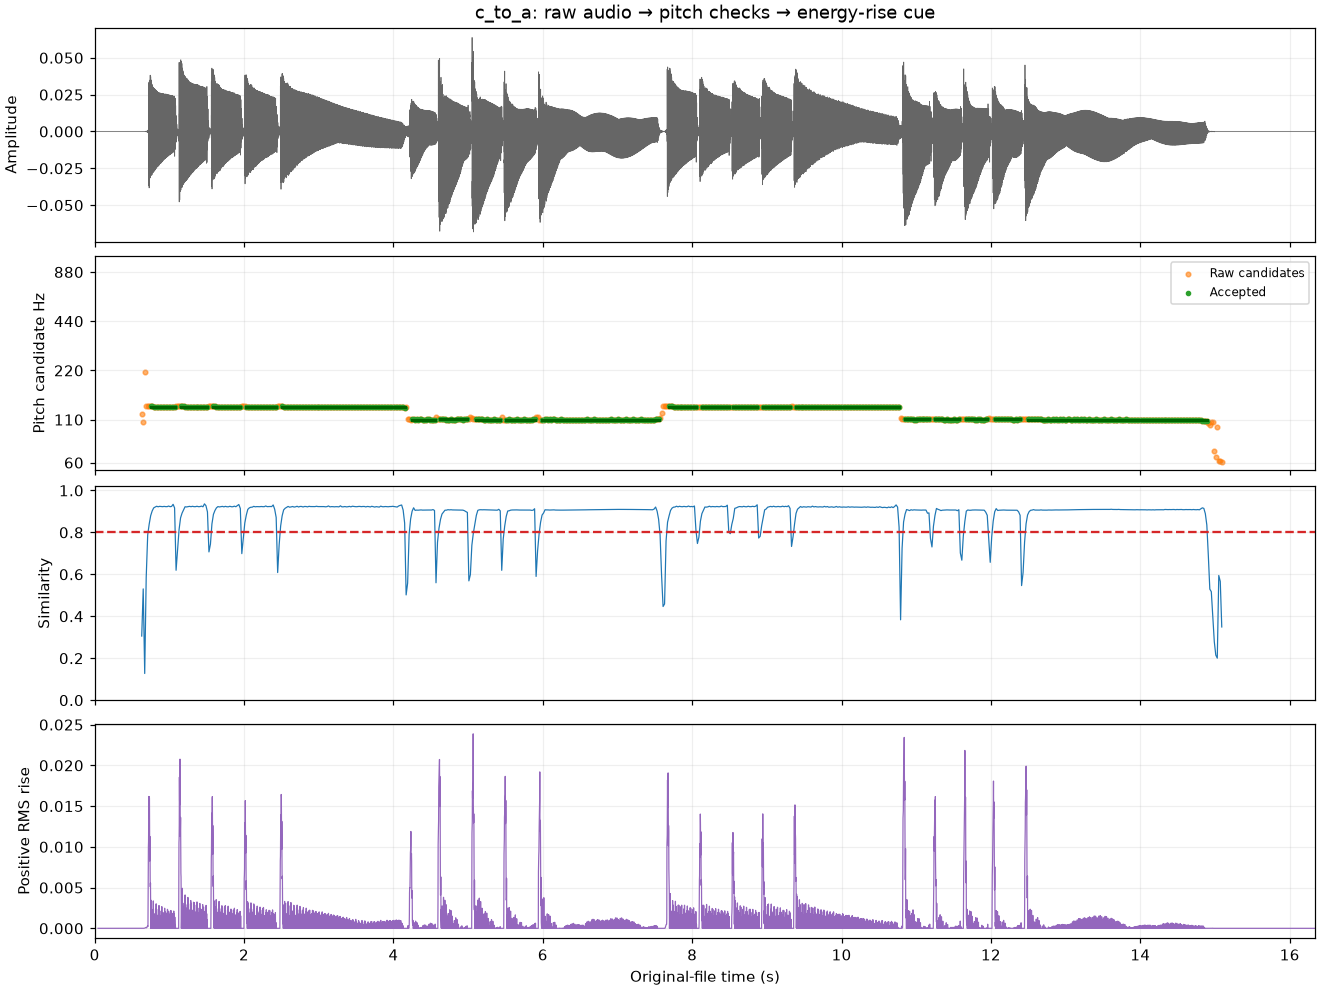

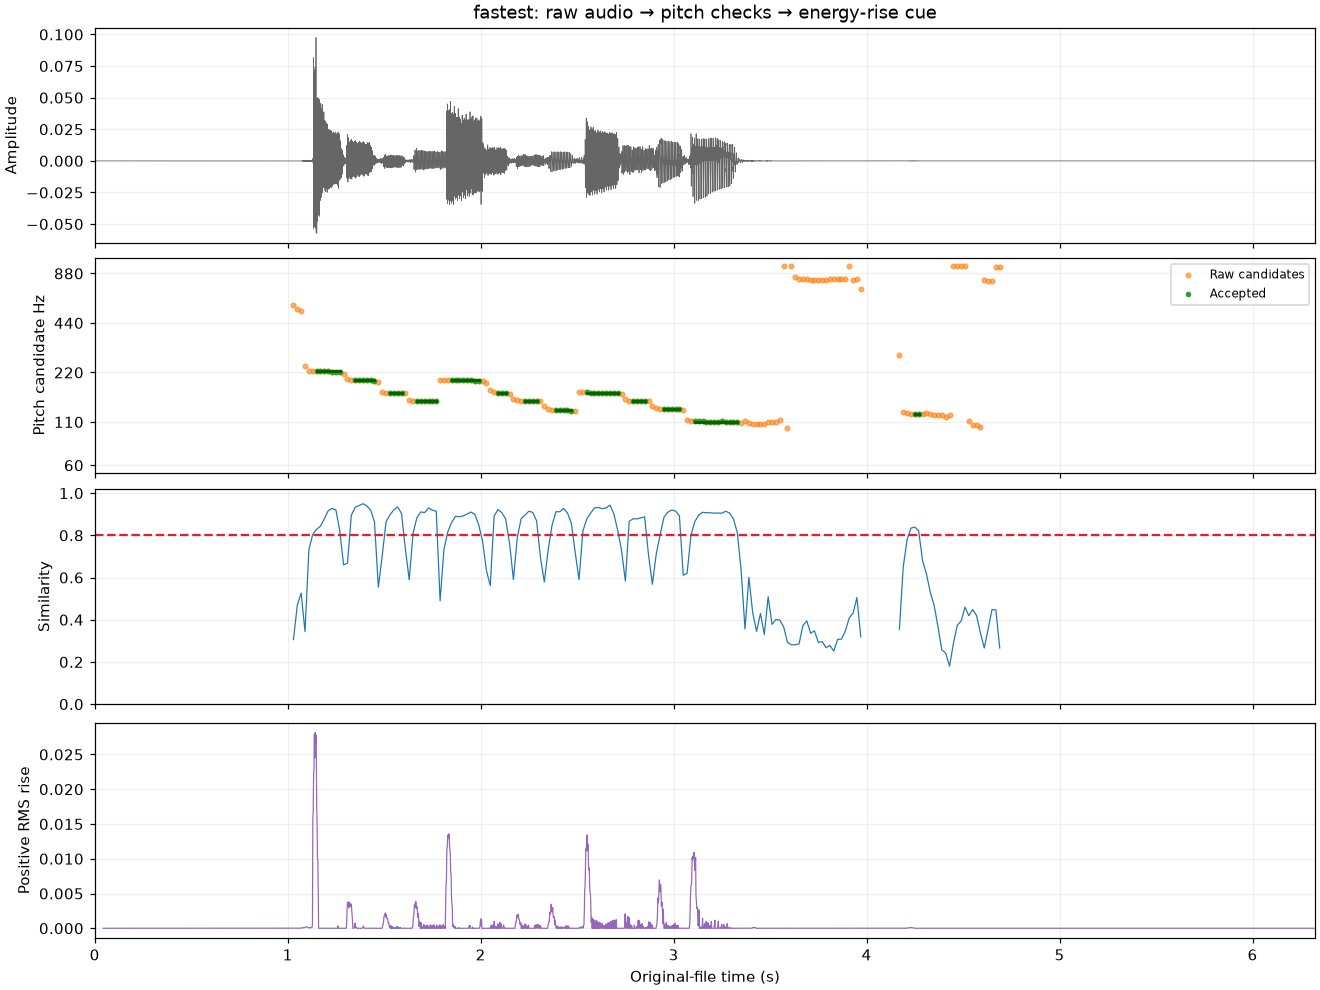

In [4]:
for identifier, result in results.items():
    rows, events, energy = result['rows'], result['events'], result['energy']
    rate = result['audit']['sample_rate']
    signal = result['signal']
    times = np.array([r['midpoint_seconds'] for r in rows])
    fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True, constrained_layout=True)
    # Display every fifth sample only; measurements always used all samples.
    axes[0].plot(np.arange(0, len(signal), 5)/rate, signal[::5], color='0.4', linewidth=.5)
    axes[0].set(ylabel='Amplitude', title=f'{identifier}: raw audio → pitch checks → energy-rise cue')
    axes[1].scatter(times, [r['candidate_hz'] for r in rows], s=9, color='tab:orange', alpha=.6, label='Raw candidates')
    axes[1].scatter(times, [r['accepted_hz'] for r in rows], s=7, color='tab:green', label='Accepted')
    for event in events:
        axes[1].plot([event['first_midpoint_seconds'], event['last_midpoint_seconds']], [event['median_hz']]*2,
                     color='darkgreen', linewidth=2)
    axes[1].set(yscale='log', ylim=(minimum_frequency*.9, maximum_frequency*1.1), ylabel='Pitch candidate Hz')
    axes[1].set_yticks([60,110,220,440,880],labels=['60','110','220','440','880'])
    axes[1].minorticks_off(); axes[1].legend(fontsize=8,loc='upper right')
    axes[2].plot(times, [r['similarity'] for r in rows], linewidth=.8)
    axes[2].axhline(minimum_similarity, color='tab:red', linestyle='--')
    axes[2].set(ylabel='Similarity', ylim=(0,1.02))
    axes[3].plot([r['midpoint_seconds'] for r in energy], [r['positive_rise'] for r in energy], color='tab:purple', linewidth=.8)
    axes[3].set(ylabel='Positive RMS rise', xlabel='Original-file time (s)')
    for ax in axes:
        ax.grid(alpha=.2);ax.set_xlim(0,len(signal)/rate)
    fig.savefig(output_folder / f'{identifier}_overview.png', dpi=140)
    plt.show()


## 4. Why repeated pitches split here—and why that is not solved in general
Inspect C-to-A's first repeated Cs. The waveform/short RMS show renewed
excitation, while the pitch stays near C3. Some 100 ms windows straddle the
attack and fail repetition; the following window may wait for continuity.
Those rejected frames split the evidence groups. The purple energy curve
does NOT cause those splits: it is an independent measurement.
Compare lesson 06's P2 repeated A4: that pair stayed accepted and merged.
Architecture question: if we removed the purple curve entirely, would these
green groups change? No—the event grouper does not consume energy yet.


First repeated-C gap:
1.07s: 131.25 Hz, similarity 0.917, accepted=True, 
1.09s: 133.23 Hz, similarity 0.619, accepted=False, weak_repetition
1.11s: 133.23 Hz, similarity 0.719, accepted=False, weak_repetition;needs_previous_eligible_window
1.13s: 133.23 Hz, similarity 0.813, accepted=False, needs_previous_eligible_window
1.15s: 133.23 Hz, similarity 0.869, accepted=True, 


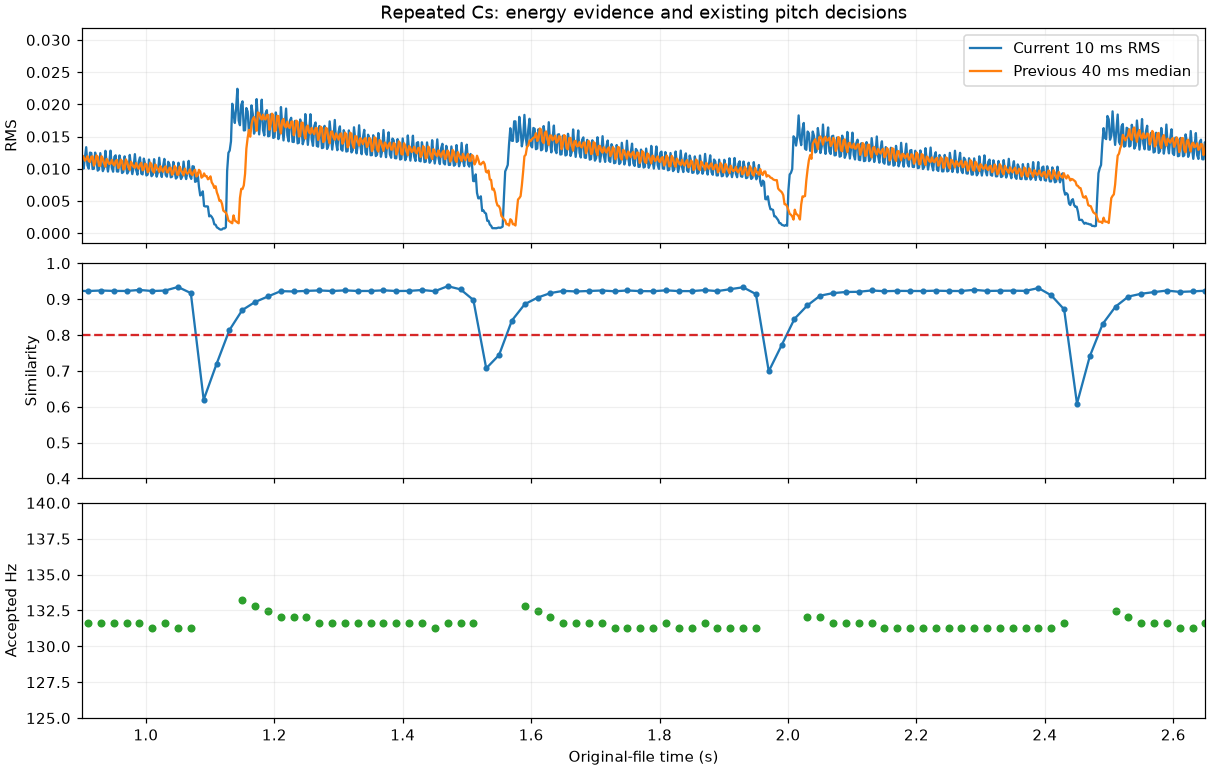

In [5]:
result = results['c_to_a']
rows, energy = result['rows'], result['energy']
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True, constrained_layout=True)
axes[0].plot([r['midpoint_seconds'] for r in energy], [r['current_rms'] for r in energy], label='Current 10 ms RMS')
axes[0].plot([r['midpoint_seconds'] for r in energy], [r['past_median_rms'] for r in energy], label='Previous 40 ms median')
axes[0].set(ylabel='RMS', title='Repeated Cs: energy evidence and existing pitch decisions'); axes[0].legend()
axes[1].plot([r['midpoint_seconds'] for r in rows], [r['similarity'] for r in rows], '.-')
axes[1].axhline(minimum_similarity, color='tab:red', linestyle='--')
axes[1].set(ylabel='Similarity', ylim=(.4,1))
axes[2].scatter([r['midpoint_seconds'] for r in rows], [r['accepted_hz'] for r in rows], color='tab:green', s=18)
axes[2].set(ylabel='Accepted Hz', ylim=(125,140), xlabel='Original-file time (s)')
for ax in axes:
    ax.set_xlim(.9,2.65); ax.grid(alpha=.2)
fig.savefig(output_folder / 'repeated_C_review.png', dpi=140)
plt.show()
print('First repeated-C gap:')
for row in rows:
    if 1.07 <= row['midpoint_seconds'] <= 1.15:
        print(f"{row['midpoint_seconds']:.2f}s: {row['candidate_hz']:.2f} Hz, similarity {row['similarity']:.3f}, accepted={row['accepted']}, {row['rejection_reasons']}")


## 5. Verdict and next experiment
Baseline and Faster yield exactly the reported 12 pitch classes in order:
A G E D G E D C E D C A. Predicted octaves are A3 initially and A2 finally;
the user subsequently confirmed fifth-position playing from D-string A to
low-E-string A, consistent with A3→A2 in standard tuning. Dynamics yields that
same phrase plus an earlier E2 group at 0.81–1.09 s. User hears no intended note
there: unwanted relative to the phrase, physical source unresolved. Do not
hide it or change a threshold just to remove it.
C-to-A yields 20 groups: five C3, five A2, five C3, five A2. The user confirmed
the pluck count. Group counts and overlapping passing-frame counts are not accuracy.
Added Fastest: same 12 pitches plus B2 at 4.25–4.27 s after the phrase.
75/312 windows pass, 13 groups. First-to-final intended group starts span
1.96 s (~52% shorter than baseline), with only 3–9 accepted frames supporting
several intermediate notes. A late unwanted group remains visible.
The faster phrase's first-to-final group-start span is 3.28 s versus 4.10 s
for baseline (~20% shorter); this is still only a modest speed increase.
Soft notes can have small energy rises despite correct pitch. A single large
absolute attack threshold chosen from the accented notes could miss them.

Next: notebook 09 implements an explicit attack-candidate rule and exposes
mistakes. Review a few audible plucks and label approximate onset intervals.
Reserve a NEW recording for evaluation (these five have now been inspected).
Keep pitch estimation, acceptance, attack detection, event assembly, and
eventual string/fret assignment separate. Continuous pitch will matter for
bends/slides; nearest-note grouping alone can turn one bend into many notes.
No timed labels or listening check were used here, and the noise reference
remains provisional. Original source indices are exported for reproducibility.
At 44,100 Hz: pitch width 4,410 samples, hop 882; energy width 441, history
1,764, hop round(88.2)=88 samples (~1.995 ms). Timing uses these actual indices,
never an assumed exact 2 ms grid. A midpoint is a display position, not an onset.
